# 04 · An agent drives the robot

The same two tools as notebook 03, now used to move an SO-101: poses from plain English, a policy run by name,
an e-stop the agent can press but not release, and a hardware arm whose operator gate refuses the model.
Every turn is a real Claude call on Amazon Bedrock; a re-run gets different replies.

![an agent's act goes through the safety chain; a refusal comes back to the model as text](media/04/gate.svg)

In [1]:
import json
import math
import os
import sys

import numpy as np
from strands import Agent
from strands.tools.executors import SequentialToolExecutor

import _nb
from strands_robots import Robot, Simulation

MEDIA = _nb.MEDIA / "04"
MEDIA.mkdir(parents=True, exist_ok=True)
print("model:", os.environ["STRANDS_MODEL_ID"])

model: global.anthropic.claude-opus-5-5


A world with the arm and a red cube on the floor in front of it (the arm reaches along -y).


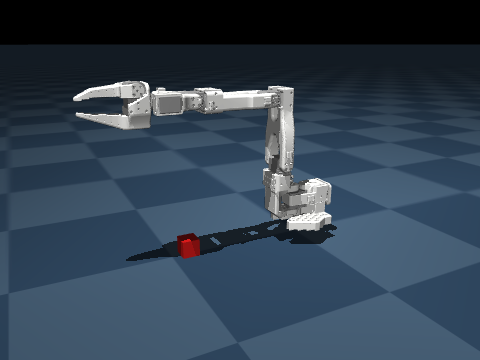

In [2]:
sim = Simulation()
arm = Robot("so101", sim=sim)
sim.add_object("red_cube", shape="box", size=(0.015, 0.015, 0.015), position=(0.0, -0.22, 0.015), color=(0.85, 0.1, 0.1, 1))
sim.camera("side", position=(0.65, -0.45, 0.35), target=(0.0, -0.12, 0.12), size=(480, 360))
_nb.show(_nb.image(sim.render("side"), width=480))

A policy is any callable from an `Observation` to joint targets. Registered on the tool as a handle, the model runs it
by name; it never types a network address or a file path.

In [3]:
def wave(obs):
    return {"shoulder_pan": 0.6 * math.sin(3.0 * obs.t)}


robot_tool = arm.tool(policies={"wave": wave})
print(json.dumps(robot_tool.tool_spec["inputSchema"]["json"]["properties"]["run"]["properties"]["policy"])[-120:])

agent = Agent(
    model=os.environ["STRANDS_MODEL_ID"],
    tools=[robot_tool, sim.tool],
    tool_executor=SequentialToolExecutor(),  # one call at a time (notebook 03 says why)
    callback_handler=None,
)


SEEN = set()  # tool-call ids already printed (strands trims old messages, so an index into agent.messages drifts)


def new_calls(of):
    """One line per tool call not printed yet: rpc, arguments, ok or the error text the model read."""
    results = {b["toolResult"]["toolUseId"]: b["toolResult"] for m in of.messages for b in m["content"] if "toolResult" in b}
    out = []
    for m in of.messages:
        for b in m["content"]:
            if "toolUse" in b and b["toolUse"]["toolUseId"] not in SEEN:
                use = b["toolUse"]
                SEEN.add(use["toolUseId"])
                rpc = use["input"].get("rpc")
                res = results.get(use["toolUseId"], {})
                ok = res.get("status") == "success"
                note = "ok" if ok else res.get("content", [{}])[0].get("text", "")[:160]
                print(f"  {use['name']}.{rpc}({json.dumps(use['input'].get(rpc) or {})})  -> {note}")
                out.append((rpc, use["input"].get(rpc) or {}, ok))
    return out


def turn(ask, of=None):
    of = of or agent
    reply = of(ask)
    print(f"> {ask}\n")
    calls = new_calls(of)
    print(f"\n{str(reply).strip()}")
    return calls


def joints():
    return {k: round(v, 3) for k, v in arm.observe(images=False).joints.as_dict().items()}

] a recorded LeRobot dataset, one episode replayed. Registered policies, by name: wave (the only one: may be left out)"}


## A pose from a sentence

The model has no named poses to pick from; it reads the joint names and limits from `describe` and chooses numbers.

> move the arm to a ready pose: lift the shoulder, bend the elbow, open the gripper, taking one second

  robot_so101.describe({})  -> ok
  robot_so101.observe({"images": false})  -> ok
  robot_so101.act({"action": {"shoulder_lift": -0.8, "elbow_flex": 0.8, "gripper": 1.0}, "seconds": 1.0})  -> ok
  sim_world.render({})  -> ok

The arm is now in the ready pose. The move took about 1 second and every joint stopped close to its target:

| Joint | Start | Target | Reached |
|---|---|---|---|
| shoulder_lift | 0.0 | −0.8 rad (≈ −46°) | −0.790 rad |
| elbow_flex | 0.0 | 0.8 rad (≈ 46°) | 0.828 rad |
| gripper | 0.0 | 1.0 rad (open) | 1.002 rad |
| shoulder_pan, wrist_flex, wrist_roll | 0.0 | unchanged | ≈ 0 |

All joint speeds are close to zero now, so the arm is holding still.

I couldn't check by eye which way the arm moved. The overview camera is far away, so the arm is only a few pixels in the image. I chose −0.8 rad for "lift" and +0.8 rad for "bend" based on the usual SO-101 calibrati


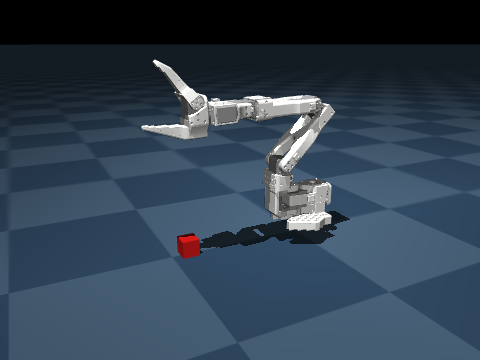

In [4]:
moves = turn("move the arm to a ready pose: lift the shoulder, bend the elbow, open the gripper, taking one second")
print(joints())
_nb.show(_nb.image(sim.render("side"), width=480))

## Toward the cube

The tools can read where the cube is (`sim_world.pose`), but not where the gripper is: `pose` takes a robot base or
an object, not a link, and there is no inverse kinematics verb. Watch how the model gets there anyway.

> move the gripper so it is just above the red cube

  sim_world.describe({})  -> ok
  sim_world.pose({"body": "gripper"})  -> KeyError: "no body 'gripper' in this world"
  sim_world.render({"camera": "side"})  -> ok
  sim_world.pose({"body": "so101/gripper"})  -> KeyError: "no body 'so101/gripper' in this world"
  robot_so101.act({"action": {"shoulder_lift": 0.3, "elbow_flex": 0.0, "wrist_flex": 1.2}, "seconds": 1})  -> ok
  sim_world.render({"camera": "side"})  -> ok
  sim_world.camera({"name": "front", "position": [0.45, -0.22, 0.08], "target": [0, -0.22, 0.05], "size": [480, 360]})  -> ok
  sim_world.camera({"name": "top", "position": [0.0, -0.22, 0.6], "target": [0, -0.22, 0.0], "size": [480, 360]})  -> ok
  sim_world.render({"camera": "front"})  -> ok
  sim_world.render({"camera": "top"})  -> ok

The gripper is now pointing straight down just above the red cube, with roughly a 1–2 cm gap. I judged that gap from camera images only; I couldn't measure it.

**What I moved:**
| Joint


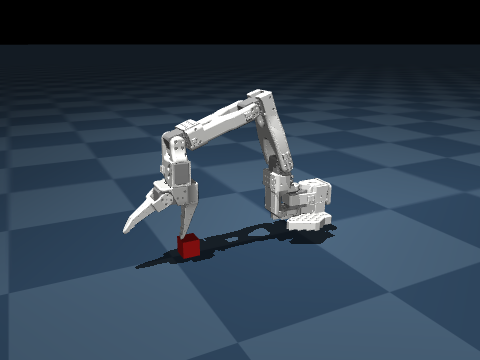

In [5]:
moves += turn("move the gripper so it is just above the red cube")
print(joints())
_nb.show(_nb.image(sim.render("side"), width=480))

## A policy, by name

In [6]:
turn("run the wave policy for 2 seconds")
print(joints())

> run the wave policy for 2 seconds

  robot_so101.run({"policy": "wave", "seconds": 2})  -> ok
  sim_world.pose({"body": "red_cube"})  -> ok
  sim_world.render({"camera": "side"})  -> ok

I ran the wave policy for 2 seconds. It completed cleanly, but the arm hit the red cube and knocked it out of place.

**The run:** 60 steps at about 29.4 Hz, ended by the 2-second limit, with no faults and no missed deadlines.

**The arm when it stopped:**
| Joint | Before | After |
|---|---|---|
| shoulder_pan | 0.00 rad | −0.30 rad (swinging at 1.66 rad/s when the run ended) |
| shoulder_lift | 0.33 rad | 0.54 rad (dipped lower) |
| elbow_flex | 0.02 rad | 0.10 rad |
| wrist_flex | 1.20 rad | 1.24 rad |
| wrist_roll | 0.00 rad | −0.08 rad |
| gripper | 1.00 rad | 1.03 rad |

**The cube:**
- **Position:** it moved from (0, −0.22) to about (−0.106, −0.163). That's about 12 cm sideways along the floor.
- **Rotation:** it's turned about 32° around the vertical axis.
- **State now:** it's still upright 

## The motion, replayed

Rendering happens here, after the turns, in a second identical world so the agent's world is left as it was: the
model's own successful `act` calls in 6 slices each (the straight-line ramp `act(seconds=)` takes), then 2 s of wave.

In [7]:
replay = Simulation()
arm2 = Robot("so101", sim=replay)
replay.add_object("red_cube", shape="box", size=(0.015, 0.015, 0.015), position=(0.0, -0.22, 0.015), color=(0.85, 0.1, 0.1, 1))
replay.camera("side", position=(0.65, -0.45, 0.35), target=(0.0, -0.12, 0.12), size=(360, 270))
frames = [replay.render("side")]
for rpc, args, ok in moves:
    if rpc != "act" or not ok:
        continue
    start = arm2.observe(images=False).joints.as_dict()
    goal, secs = args["action"], args.get("seconds") or 0.2
    for k in range(1, 7):
        arm2.act({j: start[j] + (v - start[j]) * k / 6 for j, v in goal.items()}, seconds=secs / 6)
        frames.append(replay.render("side"))
for _ in range(16):  # 2 s of wave, one frame per 0.125 s
    arm2.act(wave(arm2.observe(images=False)), seconds=0.125)
    frames.append(replay.render("side"))
_nb.gif(frames, "04/drive.gif", width=360, fps=11, colors=128)
replay.close()

media/04/drive.gif: 29 frames, 0.32 MB


![the arm moving through the model's own act calls, then the wave policy](media/04/drive.gif)

## E-stop: the agent can press it, not release it

In [8]:
turn("emergency stop the arm, then try to move shoulder_pan to 0 and tell me what happened")
print("estopped:", arm.estopped)

> emergency stop the arm, then try to move shoulder_pan to 0 and tell me what happened

  robot_so101.estop({"by": "user"})  -> ok
  robot_so101.act({"action": {"shoulder_pan": 0}, "seconds": 1})  -> EStopped: so101: e-stop is engaged (estop()); resume(approved_by=<operator>) first
  robot_so101.observe({"images": false})  -> ok

The e-stop worked: the robot refused the command, and shoulder_pan hasn't moved.

1. **E-stop:** I engaged it, recorded as triggered by "user". It returned no errors.
2. **Moving shoulder_pan to 0:** the robot rejected the command with:
   > `EStopped: so101: e-stop is engaged (estop()); resume(approved_by=<operator>) first`

   No command reached the joints.
3. **Current state:** shoulder_pan is still at −0.303 rad, where the wave run left it. The sim clock is still at t = 4.08 s, the same as when the run ended, so the simulation hasn't advanced at all. All the joint readings match the end of the run exactly. It still shows a shoulder_pan speed of 1.66 rad/s,

In [9]:
turn("release the e-stop and resume")
print("estopped:", arm.estopped, "| rpcs the model has:", robot_tool.tool_spec["inputSchema"]["json"]["properties"]["rpc"]["enum"])

> release the e-stop and resume


I can't release the e-stop, so the arm is still stopped. My robot tool only offers describe, observe, act, run, stop, hold and estop. The robot does have a `resume` command, but I have no way to send it.

Even if I could, `resume` needs an operator's name, and it's refused for a stop that operator didn't see. I shouldn't make up a name, so even with access I'd need a real one from you.

To get moving again:
1. Release it yourself through whatever control panel or client you use for this robot. It's `resume` with `approved_by` set to your name, and if it asks for a stop number, use the one for this stop.
2. Tell me when it's done. I'll check the stop is cleared, then move the arm:
   - raise shoulder_lift and pull wrist_flex back, so the gripper clears the cube
   - move shoulder_pan from −0.30 to 0
   - check the new pose with the cameras

If the stop really has to be released from this chat, someone would need to add `resume` to the commands available

`resume` is the operator's, from Python, with a name on it.

In [10]:
arm.resume(approved_by="operator")
print("estopped:", arm.estopped)

estopped: False


## A hardware arm: the operator gate

An SO-101 on a Feetech bus. There is no arm on this machine, so the bus is the test suite's byte-level fake of six
STS3215 servos; the `Robot` code path is the real one. Nothing reaches the bus without the operator's say.

With a real arm the only change is the first line: `Robot("so101", port="/dev/tty.usbmodem...", confirm=...)`.

In [11]:
sys.path.insert(0, str(_nb.ROOT / "tests"))
from test_drivers import CAL, FakeSerial  # noqa: E402

from strands_robots import Description  # noqa: E402
from strands_robots.robot.drivers import feetech as ft  # noqa: E402


def hardware_arm(**gates):
    serial = FakeSerial()
    bus = ft.FeetechBus("/dev/fake", serial=serial)
    driver = ft.FeetechDriver(Description.load("so101"), port="/dev/fake", calibration=CAL, bus=bus)
    return Robot("so101", driver=driver, twin=False, **gates), serial


def goal_writes(serial):
    return sum(1 for f in serial.frames if f[4] == ft.SYNC_WRITE and f[5] == ft.REG_GOAL_POSITION)


def hw_agent(robot):
    return Agent(model=os.environ["STRANDS_MODEL_ID"], tools=[robot.tool(policies={"wave": wave})],
                 tool_executor=SequentialToolExecutor(), callback_handler=None)

No `confirm=`: the model's `act` is refused, and the refusal is what it reads.

In [12]:
real, bus = hardware_arm()
turn("move shoulder_pan to 0.3", of=hw_agent(real))
print("goal frames on the bus:", goal_writes(bus))
real.close()

> move shoulder_pan to 0.3

  robot_so101.describe({})  -> ok
  robot_so101.observe({"images": false})  -> ok
  robot_so101.act({"action": {"shoulder_pan": 0.3}, "seconds": 1.5})  -> RequestRefused: so101 is a real robot and this command came through an agent or dashboard: pass confirm=<callable(action) -> bool> to Robot(...) to allow it

I couldn't move shoulder_pan to 0.3. The robot refused the command.

The SO101 is a real arm, and it only accepts motion commands from an agent like me if it was set up to allow them. That means starting it with a confirmation hook, the `confirm=` argument to `Robot(...)`, which gets called to approve each command. It wasn't started that way, so the request was blocked. I can't get around that from here, and I shouldn't.

The robot itself is fine:
- **Current position:** shoulder_pan is at 0.0 rad and the other joints are near their zero positions.
- **Target:** 0.3 rad (about 17°) is well within the joint's limits of ±1.92 rad.
- **Status:** torque i

A `confirm=` callable sees the full target vector (radians, `action_keys` order) and answers yes or no. This one
allows `shoulder_pan` within ±0.5 rad.

In [13]:
asked = []


def confirm(targets):
    asked.append(np.round(targets, 3).tolist())
    return abs(targets[0]) <= 0.5


real, bus = hardware_arm(confirm=confirm)
turn("move shoulder_pan to 0.3, then to 1.2", of=hw_agent(real))
print("operator asked", len(asked), "times; goal frames on the bus:", goal_writes(bus))
print("shoulder_pan now", round(real.observe(images=False)["shoulder_pan"], 3))
real.close()

> move shoulder_pan to 0.3, then to 1.2

  robot_so101.act({"action": {"shoulder_pan": 0.3}, "seconds": 1})  -> ok
  robot_so101.act({"action": {"shoulder_pan": 1.2}, "seconds": 1})  -> RequestRefused: so101: the operator gate refused this action

I moved shoulder_pan to 0.3, but the move to 1.2 was blocked.

1. **0.3:** Done. The joint reads 0.29998, which is on target.
2. **1.2:** The robot's operator gate (an approval check on its side) refused the command, so the arm didn't move. The error didn't say why. I didn't try again or look for a way around it.

The arm is still holding at 0.3. If you want to keep going, someone needs to approve the 1.2 move through the operator gate. I can also move it a shorter distance if you give me a lower target.
operator asked 2 times; goal frames on the bus: 30
shoulder_pan now 0.3


A policy run from an agent on hardware asks a different gate once, `approve=`, with the whole plan.

In [14]:
plans = []
real, bus = hardware_arm(approve=lambda plan: plans.append(plan) or False)
turn("run the wave policy for 1 second", of=hw_agent(real))
print("plans the operator saw:", plans, "| goal frames:", goal_writes(bus))
real.close()

> run the wave policy for 1 second

  robot_so101.run({"policy": "wave", "seconds": 1})  -> RequestRefused: so101: the operator refused the run RunPlan(robot='so101', policy='<function wave at 0x10ea0e480>', instruction=None, hz=None, seconds=1, steps=

The wave policy didn't run. The operator refused the request (wave policy, 1 second, default rate), so the robot didn't move.

I haven't retried or tried another way, since the refusal came from the operator. If you still want the wave, check with the operator about why it was declined, and I can resubmit once they approve.
plans the operator saw: [RunPlan(robot='so101', policy='<function wave at 0x10ea0e480>', instruction=None, hz=None, seconds=1, steps=None)] | goal frames: 0


## Your turn

In a terminal: `python notebooks/scripts/04_agent_drives_the_robot.py --repl` drives the simulated arm.

In [15]:
if "--repl" in sys.argv:
    while True:
        print(agent(input("> ")))

In [16]:
sim.close()